In [1]:
# Load the required libraries and saved model
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

# Project paths
DATA_PATH = Path("../data/CIC-IDS-2017-V2.csv")
MODEL_PATH = Path("../models/etie_isolation_forest_candidate.joblib")

# Load the saved Isolation Forest
candidate_model = joblib.load(MODEL_PATH)

print("Libraries loaded successfully.")
print("Dataset file exists:", DATA_PATH.exists())
print("Model file exists:", MODEL_PATH.exists())
print("Number of features expected:", candidate_model.n_features_in_)
print("Number of trees:", len(candidate_model.estimators_))

Libraries loaded successfully.
Dataset file exists: True
Model file exists: True
Number of features expected: 78
Number of trees: 50


In [2]:
# Load the dataset and prepare the feature columns
df = pd.read_csv(DATA_PATH)

# Separate labels from model features
FEATURE_COLUMNS = [
    col for col in df.columns
    if col != "label"
]

# Create feature and label data
X = df[FEATURE_COLUMNS]
y = df["label"]

# Verify compatibility with the saved model
print("Dataset shape:", df.shape)
print("Number of features:", len(FEATURE_COLUMNS))
print("Model expects:", candidate_model.n_features_in_)

print(
    "Feature count matches model:",
    len(FEATURE_COLUMNS) == candidate_model.n_features_in_
)

print("\nFirst five feature names:")
print(FEATURE_COLUMNS[:5])

print("\nLabel counts:")
print(y.value_counts().head())

Dataset shape: (2695162, 79)
Number of features: 78
Model expects: 78
Feature count matches model: True

First five feature names:
['Destination_Port', 'Flow_Duration', 'Total_Fwd_Packets', 'Total_Backward_Packets', 'Total_Length_of_Fwd_Packets']

Label counts:
label
BENIGN      2096484
DoS Hulk     172849
Comb         172800
DDoS         128016
PortScan      90819
Name: count, dtype: int64


In [3]:
# Select only benign traffic
benign_df = df[df["label"] == "BENIGN"]

# Select a reproducible reference sample
benign_reference = benign_df[FEATURE_COLUMNS].sample(
    n=20000,
    random_state=42
)

# Calculate reference statistics for every feature
benign_reference_stats = benign_reference.describe().T

print("Benign reference shape:", benign_reference.shape)

print("\nReference statistics for selected features:")
print(
    benign_reference_stats.loc[
        [
            "Flow_Duration",
            "Flow_Bytes/s",
            "Flow_Packets/s",
            "Total_Fwd_Packets",
            "Total_Backward_Packets"
        ],
        ["mean", "std", "min", "50%", "max"]
    ].round(4)
)

Benign reference shape: (20000, 78)

Reference statistics for selected features:
                          mean     std     min     50%     max
Flow_Duration           0.0985  0.2570  0.0000  0.0003  1.0000
Flow_Bytes/s            0.1127  0.0113  0.1093  0.1119  0.5579
Flow_Packets/s          0.3425  0.0368  0.0000  0.3333  0.8333
Total_Fwd_Packets       0.0000  0.0008  0.0000  0.0000  0.0885
Total_Backward_Packets  0.0000  0.0008  0.0000  0.0000  0.0975


In [4]:
# Select a reproducible sample of attack flows
attack_sample = df[df["label"] != "BENIGN"].sample(
    n=10000,
    random_state=42
).copy()

# Keep the same 78 features and column order
X_attack_sample = attack_sample[FEATURE_COLUMNS]

# Calculate raw Isolation Forest scores
attack_sample["raw_score"] = candidate_model.score_samples(
    X_attack_sample
)

# Lower raw scores indicate more anomalous flows
top_attack_examples = attack_sample.nsmallest(
    5, "raw_score"
)

print("Five most anomalous flows in our sample:")
print(
    top_attack_examples[
        ["label", "raw_score"]
    ].to_string(index=False)
)

Five most anomalous flows in our sample:
   label  raw_score
DoS Hulk  -0.720045
DoS Hulk  -0.715803
DoS Hulk  -0.703293
DoS Hulk  -0.699607
DoS Hulk  -0.698122


In [5]:
# Select the most anomalous flow
suspicious_flow = top_attack_examples.iloc[0]

# Get its feature values
suspicious_values = suspicious_flow[FEATURE_COLUMNS].astype(float)

# Calculate benign reference mean and standard deviation
reference_mean = benign_reference.mean()
reference_std = benign_reference.std()

# Avoid division by zero for constant features
safe_std = reference_std.replace(0, np.nan)

# Calculate standardized deviations
z_scores = (suspicious_values - reference_mean) / safe_std

# Create an explanation table
explanation_df = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "suspicious_value": suspicious_values.values,
    "benign_mean": reference_mean.values,
    "benign_std": reference_std.values,
    "z_score": z_scores.values
})

explanation_df["absolute_deviation"] = (
    explanation_df["z_score"].abs()
)

# Exclude undefined values and show the largest deviations
explanation_df = explanation_df.dropna(
    subset=["absolute_deviation"]
)

top_deviations = explanation_df.nlargest(
    10, "absolute_deviation"
)

print("Selected flow label:", suspicious_flow["label"])
print("Raw anomaly score:", round(suspicious_flow["raw_score"], 6))

print("\nTop 10 feature deviations:")
print(
    top_deviations[
        [
            "feature",
            "suspicious_value",
            "benign_mean",
            "z_score"
        ]
    ].round(6).to_string(index=False)
)

Selected flow label: DoS Hulk
Raw anomaly score: -0.720045

Top 10 feature deviations:
               feature  suspicious_value  benign_mean   z_score
Packet_Length_Variance          0.598214     0.005348 23.079530
 Bwd_Packet_Length_Std          0.707473     0.016692 19.576095
           Bwd_IAT_Std          0.671658     0.012293 13.465915
 Bwd_Packet_Length_Max          0.593702     0.022272 13.194424
     Packet_Length_Std          0.772683     0.033378 11.357592
           Fwd_IAT_Std          0.580358     0.015137 10.530177
     Max_Packet_Length          0.467164     0.021232 10.311988
        FIN_Flag_Count          1.000000     0.011200  9.395813
Bwd_Packet_Length_Mean          0.499741     0.029862  9.259042
  Avg_Bwd_Segment_Size          0.499741     0.029862  9.259042


In [6]:
# Calculate robust benign reference statistics
reference_median = benign_reference.median()

reference_q1 = benign_reference.quantile(0.25)
reference_q3 = benign_reference.quantile(0.75)

reference_iqr = reference_q3 - reference_q1

# Avoid division by zero for constant or near-constant features
safe_iqr = reference_iqr.replace(0, np.nan)

# Compare the selected suspicious flow with the benign median
robust_deviation = (
    suspicious_values - reference_median
) / safe_iqr

robust_explanation_df = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "suspicious_value": suspicious_values.values,
    "benign_median": reference_median.values,
    "benign_q1": reference_q1.values,
    "benign_q3": reference_q3.values,
    "robust_deviation": robust_deviation.values
})

robust_explanation_df["absolute_deviation"] = (
    robust_explanation_df["robust_deviation"].abs()
)

robust_explanation_df = robust_explanation_df.dropna(
    subset=["absolute_deviation"]
)

top_robust_deviations = robust_explanation_df.nlargest(
    10, "absolute_deviation"
)

print("Top 10 robust feature deviations:")
print(
    top_robust_deviations[
        [
            "feature",
            "suspicious_value",
            "benign_median",
            "benign_q1",
            "benign_q3",
            "robust_deviation"
        ]
    ].round(6).to_string(index=False)
)

Top 10 robust feature deviations:
               feature  suspicious_value  benign_median  benign_q1  benign_q3  robust_deviation
           Bwd_IAT_Std          0.671658       0.000000        0.0   0.000097       6921.153711
          Bwd_IAT_Mean          0.272500       0.000000        0.0   0.000119       2287.372880
           Bwd_IAT_Max          0.817500       0.000000        0.0   0.000396       2064.643719
           Fwd_IAT_Std          0.580358       0.000000        0.0   0.000348       1668.059739
         Bwd_IAT_Total          0.817500       0.000000        0.0   0.000726       1125.645366
Packet_Length_Variance          0.598214       0.000042        0.0   0.000631        948.814156
 Bwd_Packet_Length_Std          0.707473       0.000000        0.0   0.001208        585.635931
           Fwd_IAT_Max          0.817500       0.000000        0.0   0.001478        553.205865
          Fwd_IAT_Mean          0.204167       0.000000        0.0   0.000504        404.872673
      

In [7]:
# Calculate the benign reference's 5th and 95th percentiles
reference_p05 = benign_reference.quantile(0.05)
reference_p95 = benign_reference.quantile(0.95)

# Collect the suspicious flow's values
flow_values = suspicious_values

# Calculate distances outside the reference range
below_range = (reference_p05 - flow_values).clip(lower=0)
above_range = (flow_values - reference_p95).clip(lower=0)

outside_distance = below_range + above_range

# Use the full reference range as the scale.
# A minimum scale prevents division by extremely small ranges.
reference_range = reference_p95 - reference_p05
safe_range = reference_range.clip(lower=0.001)

normalized_deviation = outside_distance / safe_range

# Describe the direction of the deviation
direction = np.where(
    flow_values < reference_p05,
    "Below benign range",
    np.where(
        flow_values > reference_p95,
        "Above benign range",
        "Within benign range"
    )
)

range_explanation_df = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "flow_value": flow_values.values,
    "benign_p05": reference_p05.values,
    "benign_p95": reference_p95.values,
    "deviation": direction,
    "normalized_deviation": normalized_deviation.values
})

# Show the strongest out-of-range features
top_range_deviations = (
    range_explanation_df[
        range_explanation_df["normalized_deviation"] > 0
    ]
    .sort_values("normalized_deviation", ascending=False)
    .head(10)
)

print("Top 10 interpretable feature deviations:")
print(top_range_deviations.round(6).to_string(index=False))

Top 10 interpretable feature deviations:
               feature  flow_value  benign_p05  benign_p95          deviation  normalized_deviation
        FIN_Flag_Count    1.000000         0.0    0.000000 Above benign range           1000.000000
Packet_Length_Variance    0.598214         0.0    0.025388 Above benign range             22.562584
           Bwd_IAT_Std    0.671658         0.0    0.059429 Above benign range             10.301871
           Fwd_IAT_Std    0.580358         0.0    0.059566 Above benign range              8.743150
              Idle_Min    0.817500         0.0    0.084167 Above benign range              8.712871
           Bwd_IAT_Max    0.817500         0.0    0.085833 Above benign range              8.524272
             Idle_Mean    0.817500         0.0    0.100042 Above benign range              7.171595
              Idle_Max    0.817500         0.0    0.106708 Above benign range              6.661070
 Bwd_Packet_Length_Std    0.707473         0.0    0.097493 

In [8]:
# Create analyst-readable explanations
def explain_feature_deviations(flow_values, reference, feature_names, top_n=5):
    p05 = reference.quantile(0.05)
    p95 = reference.quantile(0.95)
    ref_range = p95 - p05

    results = []

    for feature in feature_names:
        value = float(flow_values[feature])
        low = float(p05[feature])
        high = float(p95[feature])
        width = float(ref_range[feature])

        if value < low:
            direction = "Below"
            distance = low - value
        elif value > high:
            direction = "Above"
            distance = value - high
        else:
            continue

        # Use the feature's observed central range when possible.
        # For near-zero ranges, keep the ranking finite.
        scale = max(width, 0.001)
        rank_score = distance / scale

        if width < 0.001:
            explanation = (
                f"{direction} benign range; "
                "the reference feature has very little variation"
            )
        else:
            explanation = (
                f"{direction} the benign reference's "
                "5th–95th percentile range"
            )

        results.append({
            "feature": feature,
            "flow_value": value,
            "benign_p05": low,
            "benign_p95": high,
            "deviation": direction,
            "ranking_score": rank_score,
            "explanation": explanation
        })

    results = sorted(
        results,
        key=lambda row: row["ranking_score"],
        reverse=True
    )

    return pd.DataFrame(results[:top_n])


flow_values = suspicious_values

analyst_explanation = explain_feature_deviations(
    flow_values=flow_values,
    reference=benign_reference,
    feature_names=FEATURE_COLUMNS,
    top_n=5
)

print(analyst_explanation.to_string(index=False))

               feature  flow_value  benign_p05  benign_p95 deviation  ranking_score                                                         explanation
        FIN_Flag_Count    1.000000         0.0    0.000000     Above    1000.000000 Above benign range; the reference feature has very little variation
Packet_Length_Variance    0.598214         0.0    0.025388     Above      22.562584              Above the benign reference's 5th–95th percentile range
           Bwd_IAT_Std    0.671658         0.0    0.059429     Above      10.301871              Above the benign reference's 5th–95th percentile range
           Fwd_IAT_Std    0.580358         0.0    0.059566     Above       8.743150              Above the benign reference's 5th–95th percentile range
              Idle_Min    0.817500         0.0    0.084167     Above       8.712871              Above the benign reference's 5th–95th percentile range


In [9]:
# Step 9: Improve the explanation ranking
# Identify features with meaningful variation in the benign reference.
reference_p05 = benign_reference.quantile(0.05)
reference_p95 = benign_reference.quantile(0.95)
reference_range = reference_p95 - reference_p05

MIN_REFERENCE_RANGE = 0.001

meaningful_features = [
    feature
    for feature in FEATURE_COLUMNS
    if reference_range[feature] >= MIN_REFERENCE_RANGE
]

near_constant_features = [
    feature
    for feature in FEATURE_COLUMNS
    if reference_range[feature] < MIN_REFERENCE_RANGE
]

print("Features with meaningful reference variation:", len(meaningful_features))
print("Near-constant features:", len(near_constant_features))

# Primary ranking: only features with meaningful benign variation.
primary_explanation = explain_feature_deviations(
    flow_values=suspicious_values,
    reference=benign_reference[meaningful_features],
    feature_names=meaningful_features,
    top_n=5
)

print("\nPrimary feature-deviation explanation:")
print(primary_explanation.to_string(index=False))

# Separately identify deviations among near-constant features.
near_constant_deviations = []

for feature in near_constant_features:
    value = float(suspicious_values[feature])
    low = float(reference_p05[feature])
    high = float(reference_p95[feature])

    if value < low or value > high:
        near_constant_deviations.append({
            "feature": feature,
            "flow_value": value,
            "benign_p05": low,
            "benign_p95": high,
            "deviation": "Below" if value < low else "Above"
        })

print("\nDeviations in near-constant features:")
if near_constant_deviations:
    print(pd.DataFrame(near_constant_deviations).to_string(index=False))
else:
    print("None found.")

Features with meaningful reference variation: 47
Near-constant features: 31

Primary feature-deviation explanation:
               feature  flow_value  benign_p05  benign_p95 deviation  ranking_score                                            explanation
Packet_Length_Variance    0.598214         0.0    0.025388     Above      22.562584 Above the benign reference's 5th–95th percentile range
           Bwd_IAT_Std    0.671658         0.0    0.059429     Above      10.301871 Above the benign reference's 5th–95th percentile range
           Fwd_IAT_Std    0.580358         0.0    0.059566     Above       8.743150 Above the benign reference's 5th–95th percentile range
              Idle_Min    0.817500         0.0    0.084167     Above       8.712871 Above the benign reference's 5th–95th percentile range
           Bwd_IAT_Max    0.817500         0.0    0.085833     Above       8.524272 Above the benign reference's 5th–95th percentile range

Deviations in near-constant features:
           

In [10]:
# Step 10: Build an ETIE-compatible explanation output
# Step 10A — Define the calibration function
def calculate_anomaly_score(raw_scores, reference_scores):
    sorted_reference = np.sort(reference_scores)

    ranks = np.searchsorted(
        sorted_reference,
        raw_scores,
        side="right"
    )

    percentile = ranks / len(sorted_reference)
    anomaly_score = 1 - percentile

    return anomaly_score

In [11]:
# Step 10B — Check the calibration variable
print([
    name for name in globals()
    if "calibration" in name.lower() and "score" in name.lower()
])

[]


In [12]:
print("X_calibration exists:", "X_calibration" in globals())
print("X_benign_eval exists:", "X_benign_eval" in globals())
print("benign_reference exists:", "benign_reference" in globals())

X_calibration exists: False
X_benign_eval exists: False
benign_reference exists: True


In [13]:
# Recreate the calibration data
from sklearn.model_selection import train_test_split

# Recreate unique feature keys for duplicate-aware splitting.
df["feature_key"] = pd.util.hash_pandas_object(
    df[FEATURE_COLUMNS],
    index=False
)

benign_df = df[df["label"] == "BENIGN"].copy()

# Recreate the original benign training/validation split.
benign_keys = benign_df["feature_key"].drop_duplicates()

benign_train_keys, benign_val_keys = train_test_split(
    benign_keys,
    test_size=0.20,
    random_state=42
)

benign_val_df = benign_df[
    benign_df["feature_key"].isin(benign_val_keys)
].copy()

# Recreate the calibration/evaluation split.
benign_val_keys_unique = benign_val_df["feature_key"].drop_duplicates()

calibration_keys, evaluation_keys = train_test_split(
    benign_val_keys_unique,
    test_size=0.50,
    random_state=42
)

calibration_df = benign_val_df[
    benign_val_df["feature_key"].isin(calibration_keys)
].copy()

X_calibration = calibration_df[FEATURE_COLUMNS]

print("Calibration rows:", len(X_calibration))
print("Unique calibration feature vectors:", len(calibration_keys))
print("Calibration data shape:", X_calibration.shape)

Calibration rows: 209527
Unique calibration feature vectors: 206325
Calibration data shape: (209527, 78)


In [14]:
# Calculate the raw calibration scores
raw_calibration_scores = candidate_model.score_samples(X_calibration)

print("Calibration scores calculated:", len(raw_calibration_scores))
print("Minimum raw score:", raw_calibration_scores.min())
print("Maximum raw score:", raw_calibration_scores.max())
print("Mean raw score:", raw_calibration_scores.mean())

Calibration scores calculated: 209527
Minimum raw score: -0.8082875451226649
Maximum raw score: -0.3109741453268219
Mean raw score: -0.34204042141487495


In [15]:
# Obtain the calibrated anomaly score for the selected flow.
# Use the same calibration reference scores and function from Phase 5/6.
selected_flow_df = suspicious_flow[FEATURE_COLUMNS].to_frame().T
selected_flow_df = selected_flow_df.astype(float)

selected_raw_score = candidate_model.score_samples(selected_flow_df)[0]

selected_anomaly_score = float(
    calculate_anomaly_score(
        np.array([selected_raw_score]),
        raw_calibration_scores
    )[0]
)

# Build the explanation list from the primary ranking.
top_deviations = []

for _, row in primary_explanation.iterrows():
    top_deviations.append({
        "feature": row["feature"],
        "observed_value": round(float(row["flow_value"]), 6),
        "benign_p05": round(float(row["benign_p05"]), 6),
        "benign_p95": round(float(row["benign_p95"]), 6),
        "direction": row["deviation"],
        "explanation": row["explanation"]
    })

etie_output = {
    "flow_id": "phase7_sample_dos_hulk",
    "anomaly_decision": (
        "suspicious" if selected_anomaly_score >= 0.90 else "review"
    ),
    "anomaly_score": round(selected_anomaly_score, 6),
    "score_type": "benign_reference_percentile_anomaly_score",
    "reliability": None,
    "reliability_status": "not_calibrated",
    "top_deviations": top_deviations,
    "model": "IsolationForest",
    "model_version": "candidate_1",
    "reference_size": len(benign_reference),
    "explanation_method": "benign_percentile_feature_deviation"
}

print(etie_output)

{'flow_id': 'phase7_sample_dos_hulk', 'anomaly_decision': 'suspicious', 'anomaly_score': 0.999885, 'score_type': 'benign_reference_percentile_anomaly_score', 'reliability': None, 'reliability_status': 'not_calibrated', 'top_deviations': [{'feature': 'Packet_Length_Variance', 'observed_value': 0.598214, 'benign_p05': 0.0, 'benign_p95': 0.025388, 'direction': 'Above', 'explanation': "Above the benign reference's 5th–95th percentile range"}, {'feature': 'Bwd_IAT_Std', 'observed_value': 0.671658, 'benign_p05': 0.0, 'benign_p95': 0.059429, 'direction': 'Above', 'explanation': "Above the benign reference's 5th–95th percentile range"}, {'feature': 'Fwd_IAT_Std', 'observed_value': 0.580358, 'benign_p05': 0.0, 'benign_p95': 0.059566, 'direction': 'Above', 'explanation': "Above the benign reference's 5th–95th percentile range"}, {'feature': 'Idle_Min', 'observed_value': 0.8175, 'benign_p05': 0.0, 'benign_p95': 0.084167, 'direction': 'Above', 'explanation': "Above the benign reference's 5th–95th 

In [16]:
# validate the explanation output
import json

etie_json = json.dumps(etie_output, indent=2, allow_nan=False)

print(etie_json[:2500])
print("\nJSON serialization successful.")

{
  "flow_id": "phase7_sample_dos_hulk",
  "anomaly_decision": "suspicious",
  "anomaly_score": 0.999885,
  "score_type": "benign_reference_percentile_anomaly_score",
  "reliability": null,
  "reliability_status": "not_calibrated",
  "top_deviations": [
    {
      "feature": "Packet_Length_Variance",
      "observed_value": 0.598214,
      "benign_p05": 0.0,
      "benign_p95": 0.025388,
      "direction": "Above",
      "explanation": "Above the benign reference's 5th\u201395th percentile range"
    },
    {
      "feature": "Bwd_IAT_Std",
      "observed_value": 0.671658,
      "benign_p05": 0.0,
      "benign_p95": 0.059429,
      "direction": "Above",
      "explanation": "Above the benign reference's 5th\u201395th percentile range"
    },
    {
      "feature": "Fwd_IAT_Std",
      "observed_value": 0.580358,
      "benign_p05": 0.0,
      "benign_p95": 0.059566,
      "direction": "Above",
      "explanation": "Above the benign reference's 5th\u201395th percentile range"
    },


In [17]:
# Next Phase
# Step 1 — Understand what the trees agree on
# Step 1A — Compare tree-level scores

from sklearn.ensemble._iforest import _average_path_length

# Select small, reproducible samples for this experiment.
benign_sample = (
    df[df["label"] == "BENIGN"]
    .sample(n=200, random_state=101)
)

attack_sample = (
    df[df["label"] != "BENIGN"]
    .sample(n=200, random_state=102)
)

X_reliability_test = pd.concat(
    [
        benign_sample[FEATURE_COLUMNS],
        attack_sample[FEATURE_COLUMNS]
    ],
    ignore_index=True
).to_numpy(dtype=np.float32)

sample_types = np.array(
    ["Benign"] * len(benign_sample)
    + ["Attack"] * len(attack_sample)
)

# Calculate each tree's anomaly scores.
tree_scores = np.zeros(
    (len(X_reliability_test), len(candidate_model.estimators_))
)

normalizing_length = float(
    np.asarray(
        _average_path_length([candidate_model.max_samples_])
    ).reshape(-1)[0]
)

for tree_index, (tree, feature_indices) in enumerate(
    zip(
        candidate_model.estimators_,
        candidate_model.estimators_features_
    )
):
    X_tree = X_reliability_test[:, feature_indices]

    leaf_indices = tree.apply(X_tree)

    node_counts = np.asarray(
        tree.decision_path(X_tree).sum(axis=1)
    ).reshape(-1)

    leaf_sample_counts = tree.tree_.n_node_samples[leaf_indices]

    average_leaf_lengths = np.asarray(
        _average_path_length(leaf_sample_counts)
    ).reshape(-1)

    path_lengths = (
        node_counts - 1 + average_leaf_lengths
    ).astype(float)

    tree_scores[:, tree_index] = np.exp2(
        -path_lengths / normalizing_length
    )

score_summary = pd.DataFrame({
    "sample_type": sample_types,
    "mean_tree_score": tree_scores.mean(axis=1),
    "std_tree_score": tree_scores.std(axis=1),
    "min_tree_score": tree_scores.min(axis=1),
    "max_tree_score": tree_scores.max(axis=1)
})

print("Tree-score summary by sample type:")
print(
    score_summary.groupby("sample_type")[
        [
            "mean_tree_score",
            "std_tree_score",
            "min_tree_score",
            "max_tree_score"
        ]
    ].mean().round(6)
)

Tree-score summary by sample type:
             mean_tree_score  std_tree_score  min_tree_score  max_tree_score
sample_type                                                                 
Attack              0.499312        0.129276        0.304197        0.816084
Benign              0.349790        0.044410        0.296296        0.493348


In [18]:
# Step 2 — Measure agreement with the model's final decision
# Convert each tree's score to an individual tree vote.
# The threshold is exploratory and must be validated.
TREE_THRESHOLD = 0.90

tree_votes = tree_scores >= TREE_THRESHOLD

# Fraction of trees voting that a flow is anomalous.
tree_anomaly_agreement = tree_votes.mean(axis=1)

# Compare tree votes with the saved model's calibrated anomaly score.
raw_sample_scores = candidate_model.score_samples(
    X_reliability_test
)

sample_anomaly_scores = calculate_anomaly_score(
    raw_sample_scores,
    raw_calibration_scores
)

final_decisions = sample_anomaly_scores >= TREE_THRESHOLD

agreement_summary = pd.DataFrame({
    "sample_type": sample_types,
    "anomaly_score": sample_anomaly_scores,
    "final_decision": final_decisions,
    "tree_anomaly_agreement": tree_anomaly_agreement
})

print("Tree agreement by sample type:")
print(
    agreement_summary.groupby("sample_type")[
        ["tree_anomaly_agreement"]
    ].mean().round(4)
)

print("\nMean tree agreement by final model decision:")
print(
    agreement_summary.groupby("final_decision")[
        ["tree_anomaly_agreement"]
    ].mean().round(4)
)

print("\nIndividual tree vote counts:")
print(
    pd.Series(tree_votes.sum(axis=1), name="anomalous_tree_votes")
    .describe()
    .round(2)
)

Tree agreement by sample type:
             tree_anomaly_agreement
sample_type                        
Attack                       0.0181
Benign                       0.0004

Mean tree agreement by final model decision:
                tree_anomaly_agreement
final_decision                        
False                           0.0000
True                            0.0208

Individual tree vote counts:
count    400.00
mean       0.46
std        1.05
min        0.00
25%        0.00
50%        0.00
75%        0.00
max        4.00
Name: anomalous_tree_votes, dtype: float64


c:\Users\Dilum\Desktop\ETIE\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but IsolationForest was fitted with feature names
  warnings.warn(


In [19]:
# Step 3 — Establish a better baseline for reliability
# Calculate the overall model score using the original feature names.
raw_sample_scores = candidate_model.score_samples(
    pd.DataFrame(
        X_reliability_test,
        columns=FEATURE_COLUMNS
    )
)

sample_anomaly_scores = calculate_anomaly_score(
    raw_sample_scores,
    raw_calibration_scores
)

agreement_analysis = pd.DataFrame({
    "sample_type": sample_types,
    "anomaly_score": sample_anomaly_scores,
    "tree_score_mean": tree_scores.mean(axis=1),
    "tree_score_std": tree_scores.std(axis=1),
    "tree_score_range": (
        tree_scores.max(axis=1) - tree_scores.min(axis=1)
    )
})

print("Correlation with calibrated anomaly score:")
print(
    agreement_analysis[
        ["anomaly_score", "tree_score_mean",
         "tree_score_std", "tree_score_range"]
    ].corr()["anomaly_score"].round(4)
)

print("\nTree-score variation by sample type:")
print(
    agreement_analysis.groupby("sample_type")[
        ["anomaly_score", "tree_score_std", "tree_score_range"]
    ].mean().round(4)
)

Correlation with calibrated anomaly score:
anomaly_score       1.0000
tree_score_mean     0.8046
tree_score_std      0.8177
tree_score_range    0.8647
Name: anomaly_score, dtype: float64

Tree-score variation by sample type:
             anomaly_score  tree_score_std  tree_score_range
sample_type                                                 
Attack              0.8729          0.1293            0.5119
Benign              0.5064          0.0444            0.1971


In [20]:
# Step 4 — Test whether tree variation adds useful information
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Ground-truth labels for this small exploratory sample.
y_reliability = (sample_types == "Attack").astype(int)

# Model score alone.
X_score_only = agreement_analysis[
    ["anomaly_score"]
]

# Model score plus tree-level variation.
X_score_and_variation = agreement_analysis[
    ["anomaly_score", "tree_score_std", "tree_score_range"]
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def evaluate_logistic_features(X_features, y):
    pipeline = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    )

    auc_scores = cross_val_score(
        pipeline,
        X_features,
        y,
        cv=cv,
        scoring="roc_auc"
    )

    return auc_scores

auc_score_only = evaluate_logistic_features(
    X_score_only,
    y_reliability
)

auc_score_and_variation = evaluate_logistic_features(
    X_score_and_variation,
    y_reliability
)

print("5-fold ROC-AUC: anomaly score only")
print(np.round(auc_score_only, 4))
print("Mean:", round(auc_score_only.mean(), 4))

print("\n5-fold ROC-AUC: anomaly score + tree variation")
print(np.round(auc_score_and_variation, 4))
print("Mean:", round(auc_score_and_variation.mean(), 4))

print(
    "\nMean ROC-AUC improvement:",
    round(
        auc_score_and_variation.mean() - auc_score_only.mean(),
        4
    )
)

5-fold ROC-AUC: anomaly score only
[0.8381 0.8488 0.8225 0.8838 0.9094]
Mean: 0.8605

5-fold ROC-AUC: anomaly score + tree variation
[0.9044 0.9225 0.8806 0.9031 0.9025]
Mean: 0.9026

Mean ROC-AUC improvement: 0.0421


In [21]:
# Step 5 — Test whether the improvement is consistent
fold_comparison = pd.DataFrame({
    "fold": range(1, 6),
    "score_only_auc": auc_score_only,
    "score_plus_variation_auc": auc_score_and_variation
})

fold_comparison["improvement"] = (
    fold_comparison["score_plus_variation_auc"]
    - fold_comparison["score_only_auc"]
)

print(fold_comparison.round(4).to_string(index=False))

print("\nFolds with improved ROC-AUC:",
      (fold_comparison["improvement"] > 0).sum(), "out of 5")

print("Smallest fold improvement:",
      round(fold_comparison["improvement"].min(), 4))

 fold  score_only_auc  score_plus_variation_auc  improvement
    1          0.8381                    0.9044       0.0662
    2          0.8488                    0.9225       0.0737
    3          0.8225                    0.8806       0.0581
    4          0.8838                    0.9031       0.0194
    5          0.9094                    0.9025      -0.0069

Folds with improved ROC-AUC: 4 out of 5
Smallest fold improvement: -0.0069


In [22]:
# Step 6 — Check what the added features contribute
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_features = agreement_analysis[
    ["anomaly_score", "tree_score_std", "tree_score_range"]
]

y_reliability = (sample_types == "Attack").astype(int)

diagnostic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

diagnostic_model.fit(X_features, y_reliability)

coefficients = diagnostic_model.named_steps[
    "logisticregression"
].coef_[0]

coefficient_results = pd.DataFrame({
    "feature": X_features.columns,
    "standardized_coefficient": coefficients
})

print(coefficient_results.round(4).to_string(index=False))

         feature  standardized_coefficient
   anomaly_score                   -0.5321
  tree_score_std                    0.0526
tree_score_range                    2.4884


In [23]:
# Step 7 — Check whether the variation features overlap
variation_features = agreement_analysis[
    ["anomaly_score", "tree_score_std", "tree_score_range"]
]

print(
    variation_features.corr().round(4).to_string()
)

                  anomaly_score  tree_score_std  tree_score_range
anomaly_score            1.0000          0.8177            0.8647
tree_score_std           0.8177          1.0000            0.9646
tree_score_range         0.8647          0.9646            1.0000


In [24]:
# Step 8 — Compare the two-feature model
X_score_and_range = agreement_analysis[
    ["anomaly_score", "tree_score_range"]
]

auc_score_and_range = evaluate_logistic_features(
    X_score_and_range,
    y_reliability
)

print("5-fold ROC-AUC: anomaly score + tree-score range")
print(np.round(auc_score_and_range, 4))
print("Mean:", round(auc_score_and_range.mean(), 4))

print("\nComparison of mean ROC-AUC")
print("Anomaly score only:",
      round(auc_score_only.mean(), 4))
print("Score + standard deviation + range:",
      round(auc_score_and_variation.mean(), 4))
print("Score + range only:",
      round(auc_score_and_range.mean(), 4))

5-fold ROC-AUC: anomaly score + tree-score range
[0.9112 0.9219 0.8794 0.9038 0.9031]
Mean: 0.9039

Comparison of mean ROC-AUC
Anomaly score only: 0.8605
Score + standard deviation + range: 0.9026
Score + range only: 0.9039


In [25]:
# Step 9 — Check how well the range feature separates the two classes
range_summary = agreement_analysis.groupby("sample_type")[
    "tree_score_range"
].agg(
    ["count", "mean", "std", "min", "median", "max"]
)

print(range_summary.round(4).to_string())

print("\nPercentiles by sample type:")
for sample_type in ["Benign", "Attack"]:
    values = agreement_analysis.loc[
        agreement_analysis["sample_type"] == sample_type,
        "tree_score_range"
    ]

    print(f"\n{sample_type}:")
    print(
        values.quantile([0.10, 0.25, 0.50, 0.75, 0.90])
        .round(4)
        .to_string()
    )

             count    mean     std     min  median     max
sample_type                                               
Attack         200  0.5119  0.1711  0.1031  0.5877  0.6642
Benign         200  0.1971  0.1281  0.0546  0.1562  0.6240

Percentiles by sample type:

Benign:
0.10    0.0763
0.25    0.0863
0.50    0.1562
0.75    0.2722
0.90    0.3992

Attack:
0.10    0.2017
0.25    0.4620
0.50    0.5877
0.75    0.6642
0.90    0.6642


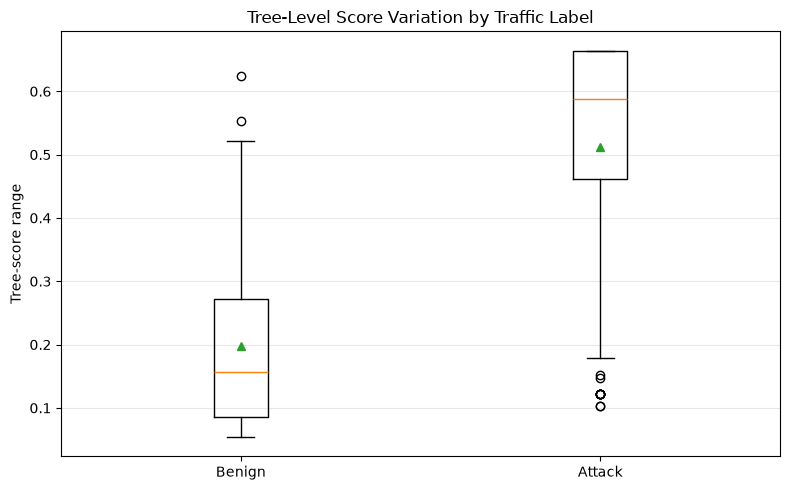

In [26]:
# Step 10 — Visualize the separation
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

benign_ranges = agreement_analysis.loc[
    agreement_analysis["sample_type"] == "Benign",
    "tree_score_range"
]

attack_ranges = agreement_analysis.loc[
    agreement_analysis["sample_type"] == "Attack",
    "tree_score_range"
]

plt.boxplot(
    [benign_ranges, attack_ranges],
    tick_labels=["Benign", "Attack"],
    showmeans=True
)

plt.ylabel("Tree-score range")
plt.title("Tree-Level Score Variation by Traffic Label")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Step 11 — Check for repeated values and saturation
for sample_type in ["Benign", "Attack"]:
    values = agreement_analysis.loc[
        agreement_analysis["sample_type"] == sample_type,
        "tree_score_range"
    ]

    print(f"\n{sample_type}")
    print("Unique values:", values.nunique())
    print("At maximum observed range (0.6642):",
          int((values.round(4) == 0.6642).sum()))
    print("At or above 0.60:",
          int((values >= 0.60).sum()))
    print("At or below 0.20:",
          int((values <= 0.20).sum()))


Benign
Unique values: 69
At maximum observed range (0.6642): 0
At or above 0.60: 1
At or below 0.20: 126

Attack
Unique values: 35
At maximum observed range (0.6642): 54
At or above 0.60: 66
At or below 0.20: 13


In [28]:
# Step 12 — Investigate the repeated maximum
# Find attack samples whose tree-score range reaches 0.6642.
max_range_mask = (
    (agreement_analysis["sample_type"] == "Attack")
    & (agreement_analysis["tree_score_range"].round(4) == 0.6642)
)

max_range_indices = agreement_analysis.index[max_range_mask]

# Recover the corresponding rows in tree_scores.
positions = agreement_analysis.index.get_indexer(max_range_indices)
max_range_tree_scores = tree_scores[positions]

print("Samples at maximum range:", len(positions))
print("Tree-score matrix shape:", max_range_tree_scores.shape)

print("\nPer-sample tree-score summaries:")
print(
    pd.DataFrame({
        "minimum": max_range_tree_scores.min(axis=1),
        "maximum": max_range_tree_scores.max(axis=1),
        "mean": max_range_tree_scores.mean(axis=1),
        "std": max_range_tree_scores.std(axis=1)
    }).round(4).head(10).to_string(index=False)
)

print("\nDistinct minimum scores:",
      np.unique(np.round(max_range_tree_scores.min(axis=1), 4)))
print("Distinct maximum scores:",
      np.unique(np.round(max_range_tree_scores.max(axis=1), 4)))

Samples at maximum range: 54
Tree-score matrix shape: (54, 50)

Per-sample tree-score summaries:
 minimum  maximum   mean    std
  0.2962   0.9604 0.4613 0.1975
  0.2962   0.9604 0.4612 0.1975
  0.2962   0.9604 0.4613 0.1975
  0.2962   0.9604 0.4639 0.1964
  0.2962   0.9604 0.4597 0.1935
  0.2962   0.9604 0.4581 0.1970
  0.2962   0.9604 0.4614 0.1963
  0.2962   0.9604 0.5017 0.2004
  0.2962   0.9604 0.4705 0.1920
  0.2962   0.9604 0.4608 0.1971

Distinct minimum scores: [0.2962]
Distinct maximum scores: [0.9604]


In [29]:
# Step 13 — Check whether those extremes come from the same trees
min_tree_indices = max_range_tree_scores.argmin(axis=1)
max_tree_indices = max_range_tree_scores.argmax(axis=1)

print("Most common minimum-score trees:")
print(
    pd.Series(min_tree_indices)
    .value_counts()
    .head(10)
    .to_string()
)

print("\nMost common maximum-score trees:")
print(
    pd.Series(max_tree_indices)
    .value_counts()
    .head(10)
    .to_string()
)

print("\nNumber of distinct minimum-score trees:",
      pd.Series(min_tree_indices).nunique())

print("Number of distinct maximum-score trees:",
      pd.Series(max_tree_indices).nunique())

Most common minimum-score trees:
11    54

Most common maximum-score trees:
12    54

Number of distinct minimum-score trees: 1
Number of distinct maximum-score trees: 1


In [30]:
# Step 14 — Inspect the two trees' score patterns
tree_comparison = pd.DataFrame({
    "sample_type": sample_types,
    "tree_11_score": tree_scores[:, 11],
    "tree_12_score": tree_scores[:, 12],
    "tree_score_range": agreement_analysis["tree_score_range"].to_numpy()
})

print(
    tree_comparison.groupby("sample_type")[
        ["tree_11_score", "tree_12_score", "tree_score_range"]
    ].agg(["mean", "std", "min", "median", "max"]).round(4)
)

print("\nCorrelation between tree 11 and tree 12 scores:")
print(
    tree_comparison[["tree_11_score", "tree_12_score"]]
    .corr()
    .round(4)
)

print("\nUnique score pairs for attack flows at maximum range:")
print(
    tree_comparison.loc[
        max_range_mask.to_numpy(),
        ["tree_11_score", "tree_12_score"]
    ].drop_duplicates().head(10).to_string(index=False)
)

            tree_11_score                                 tree_12_score  \
                     mean     std     min  median     max          mean   
sample_type                                                               
Attack             0.3891  0.1770  0.2962  0.2962  0.8860        0.6436   
Benign             0.3070  0.0709  0.2962  0.2962  0.9225        0.3669   

                                            tree_score_range                  \
                std     min  median     max             mean     std     min   
sample_type                                                                    
Attack       0.2304  0.3145  0.6679  0.9604           0.5119  0.1711  0.1031   
Benign       0.0827  0.3145  0.3387  0.7850           0.1971  0.1281  0.0546   

                             
             median     max  
sample_type                  
Attack       0.5877  0.6642  
Benign       0.1562  0.6240  

Correlation between tree 11 and tree 12 scores:
               tree_11_s

In [31]:
# Step 15 — Check the range without trees 11 and 12
# Exclude trees 11 and 12, then recalculate the score range.
tree_scores_without_11_12 = np.delete(
    tree_scores,
    [11, 12],
    axis=1
)

range_without_11_12 = (
    tree_scores_without_11_12.max(axis=1)
    - tree_scores_without_11_12.min(axis=1)
)

range_comparison = pd.DataFrame({
    "sample_type": sample_types,
    "original_range": agreement_analysis[
        "tree_score_range"
    ].to_numpy(),
    "range_without_trees_11_12": range_without_11_12
})

print(
    range_comparison.groupby("sample_type")[
        ["original_range", "range_without_trees_11_12"]
    ].agg(["mean", "median", "std"]).round(4)
)

print("\nMean range after excluding trees 11 and 12:")
print(
    range_comparison.groupby("sample_type")[
        "range_without_trees_11_12"
    ].mean().round(4)
)

            original_range                 range_without_trees_11_12          \
                      mean  median     std                      mean  median   
sample_type                                                                    
Attack              0.5119  0.5877  0.1711                    0.4937  0.5210   
Benign              0.1971  0.1562  0.1281                    0.1947  0.1542   

                     
                std  
sample_type          
Attack       0.1696  
Benign       0.1275  

Mean range after excluding trees 11 and 12:
sample_type
Attack    0.4937
Benign    0.1947
Name: range_without_trees_11_12, dtype: float64


In [32]:
# Step 16 — Compare discrimination after excluding the two trees
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Use the anomaly score and the range calculated from the remaining 48 trees.
X_score_and_reduced_range = pd.DataFrame({
    "anomaly_score": agreement_analysis["anomaly_score"].to_numpy(),
    "tree_score_range_without_11_12": range_without_11_12
})

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

auc_reduced_range = cross_val_score(
    make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),
    X_score_and_reduced_range,
    y_reliability,
    cv=cv,
    scoring="roc_auc"
)

print("5-fold ROC-AUC: anomaly score + reduced tree-score range")
print(np.round(auc_reduced_range, 4))
print("Mean:", round(auc_reduced_range.mean(), 4))

print("\nComparisons:")
print("Anomaly score only:", round(auc_score_only.mean(), 4))
print("Anomaly score + original range:", round(auc_score_and_range.mean(), 4))
print("Anomaly score + reduced range:", round(auc_reduced_range.mean(), 4))

5-fold ROC-AUC: anomaly score + reduced tree-score range
[0.9044 0.915  0.8756 0.8994 0.9012]
Mean: 0.8991

Comparisons:
Anomaly score only: 0.8605
Anomaly score + original range: 0.9039
Anomaly score + reduced range: 0.8991


In [33]:
# Step 17 — Compare the models' fold-by-fold results
fold_comparison_reduced = pd.DataFrame({
    "fold": range(1, 6),
    "score_only_auc": auc_score_only,
    "original_range_auc": auc_score_and_range,
    "reduced_range_auc": auc_reduced_range
})

fold_comparison_reduced["reduced_range_improvement"] = (
    fold_comparison_reduced["reduced_range_auc"]
    - fold_comparison_reduced["score_only_auc"]
)

print(fold_comparison_reduced.round(4).to_string(index=False))

print(
    "\nFolds where reduced range improves AUC:",
    int((fold_comparison_reduced["reduced_range_improvement"] > 0).sum()),
    "out of 5"
)

 fold  score_only_auc  original_range_auc  reduced_range_auc  reduced_range_improvement
    1          0.8381              0.9112             0.9044                     0.0662
    2          0.8488              0.9219             0.9150                     0.0663
    3          0.8225              0.8794             0.8756                     0.0531
    4          0.8838              0.9038             0.8994                     0.0156
    5          0.9094              0.9031             0.9012                    -0.0081

Folds where reduced range improves AUC: 4 out of 5
